In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.preprocessing import MinMaxScaler

In [2]:
# Membuat data suhu simulasi
# Asumsi: data historis selama 100 hari
np.random.seed(42)
temp_data = np.sin(np.arange(100) * 2 * np.pi / 25) * 5 + 25 + np.random.randn(100) * 1.5
temp_data = temp_data.reshape(-1, 1)

# Normalisasi data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(temp_data)

# Fungsi untuk membuat dataset urutan
def create_dataset(data, n_steps):
    X, y = [], []
    for i in range(len(data) - n_steps):
        seq_x, seq_y = data[i:(i + n_steps), 0], data[i + n_steps, 0]
        X.append(seq_x)
        y.append(seq_y)
    return np.array(X), np.array(y)

# Menentukan langkah waktu (n_steps)
n_steps = 10
X, y = create_dataset(scaled_data, n_steps)

# Memisahkan data training dan testing
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Reshape data untuk model RNN: [samples, timesteps, features]
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print(f"Shape data training: {X_train.shape}")
print(f"Shape data testing: {X_test.shape}")

Shape data training: (72, 10, 1)
Shape data testing: (18, 10, 1)


In [3]:
# Membangun model RNN
model = Sequential([
    SimpleRNN(50, activation='relu', input_shape=(n_steps, 1)),
    Dense(1)
])

# Kompilasi model
model.compile(optimizer='adam', loss='mean_squared_error')

# Menampilkan ringkasan model
model.summary()

# Melatih model
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_test, y_test), verbose=1)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - loss: 0.7895 - val_loss: 0.5039
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.4999 - val_loss: 0.3415
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.4009 - val_loss: 0.2418
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.2775 - val_loss: 0.1804
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.2135 - val_loss: 0.1334
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.1716 - val_loss: 0.0953
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1308 - val_loss: 0.0644
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.1022 - val_loss: 0.0444
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0799 - val_loss: 0.0370
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0632 - val_loss: 0.0419
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0538 - val_loss: 0.0452
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0546 - val_l

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step


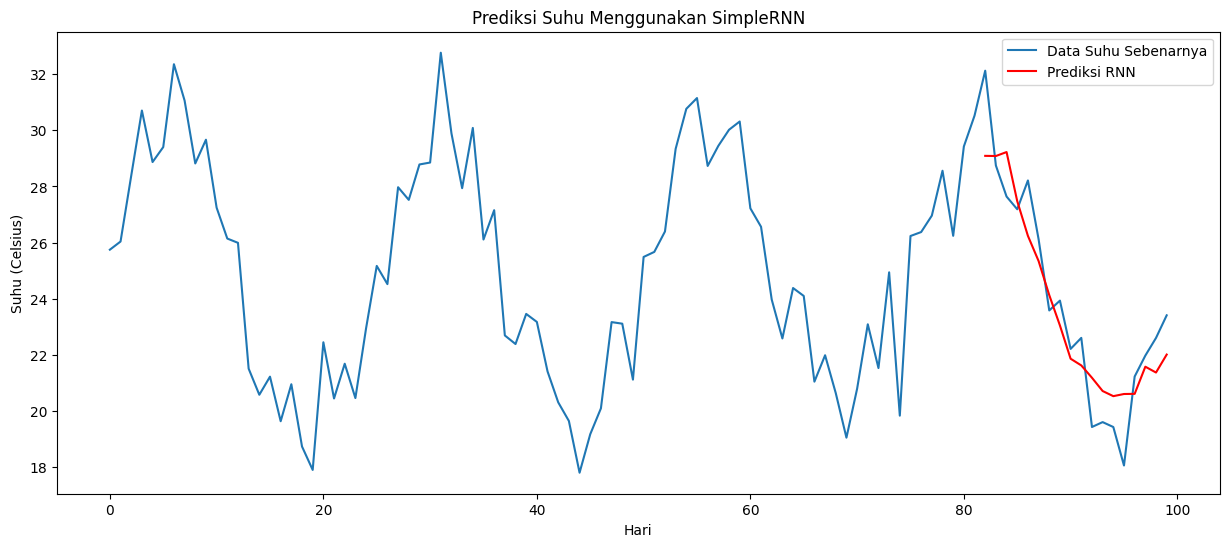


Loss pada data training: 0.0080
Loss pada data testing: 0.0086


In [4]:
# Melakukan prediksi
predictions = model.predict(X_test)

# Mengembalikan nilai ke skala asli (denormalisasi)
predictions = scaler.inverse_transform(predictions)
y_test = scaler.inverse_transform(y_test.reshape(-1, 1))

# Plot hasil
plt.figure(figsize=(15, 6))
plt.plot(temp_data, label='Data Suhu Sebenarnya')
plt.plot(np.arange(len(temp_data) - len(predictions), len(temp_data)), predictions, color='red', label='Prediksi RNN')
plt.title('Prediksi Suhu Menggunakan SimpleRNN')
plt.xlabel('Hari')
plt.ylabel('Suhu (Celsius)')
plt.legend()
plt.show()

# Menampilkan metrik
train_loss = history.history['loss'][-1]
test_loss = history.history['val_loss'][-1]
print(f"\nLoss pada data training: {train_loss:.4f}")
print(f"Loss pada data testing: {test_loss:.4f}")